# Building Smarter Agents with Reflection and Planning
### Hands-on workshop | Microsoft Foundry Agents v2 API + Responses API

**Goal:** Observe the behavioral difference between a one-shot answer, an explicit **plan → act** workflow, and an **act → critique → revise** workflow. 

All model calls use persisted Microsoft Foundry **prompt agents** and the **Responses API**.

## 1. Concept: Why should agents revisit their first answer?

- **One-shot:** a single request generates a final answer; omissions can pass unnoticed.

- **Planning:** decompose the task into explicit, checkable steps before producing the recommendation.

- **Reflection:** generate a draft, critique it against a rubric, then revise the draft.

- **Orchestration:** Python controls the loop, data, stopping conditions, and which specialized agent runs next. A prompt saying “think carefully” is *not* the same as an observable agentic loop.

In Agents v2 API, successive `openai.responses.create(...)` calls are connected by a `previous_response_id` value. The reference preserves the earlier output context; you do not need v1 threads/runs. We also pass explicit text to cross-agent stages to ensure the critic's findings reach the reviser.

**Important:** We will demonstrate visible *decision artifacts* (plan, draft, critique, revision), **not** hidden model chain-of-thought.

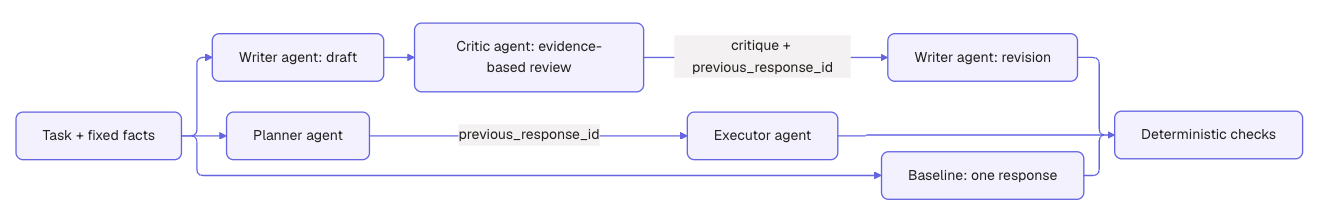

The key upgrade is not a bigger model. It is giving the workflow an opportunity to inspect its own intermediate work and correct it under explicit rules.

## 2. Prerequisites and Codespaces configuration

Either:

* Open this repository in **GitHub Codespaces**. The Codespace installs requirements and opens Jupyter automatically when the devcontainer starts. Open this notebook.

or:

* if you don't want to use GitHub Codespaces, open Visual Studio Code and open the folder containing this repository. Launch a Terminal and run this command: `python -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt && jupyter lab`. Then, open this notebook.

1. Once the notebook is open, open a terminal and run `az login --use-device-code` to sign in with your Azure account.

2. In Microsoft Foundry, create a project and deploy a model suitable for prompt agents; copy the **project endpoint** (`https://<resource>.services.ai.azure.com/api/projects/<project>`), not the raw `/openai/v1/chat/completions` URL.

3. Run `cp .env.example .env` in the terminal. 

4. Open `.env`, set the values for both `FOUNDRY_PROJECT_ENDPOINT` and `FOUNDRY_MODEL_NAME` environment variables. Never commit `.env`.

5. Select the **Python 3** kernel for this notebook.

After you create a **Foundry** resource in the Azure portal, go to the **Foundry portal** and you can find the **Project endpoint** in **Home** page. Use this value for the `FOUNDRY_PROJECT_ENDPOINT` environment variable in `.env`

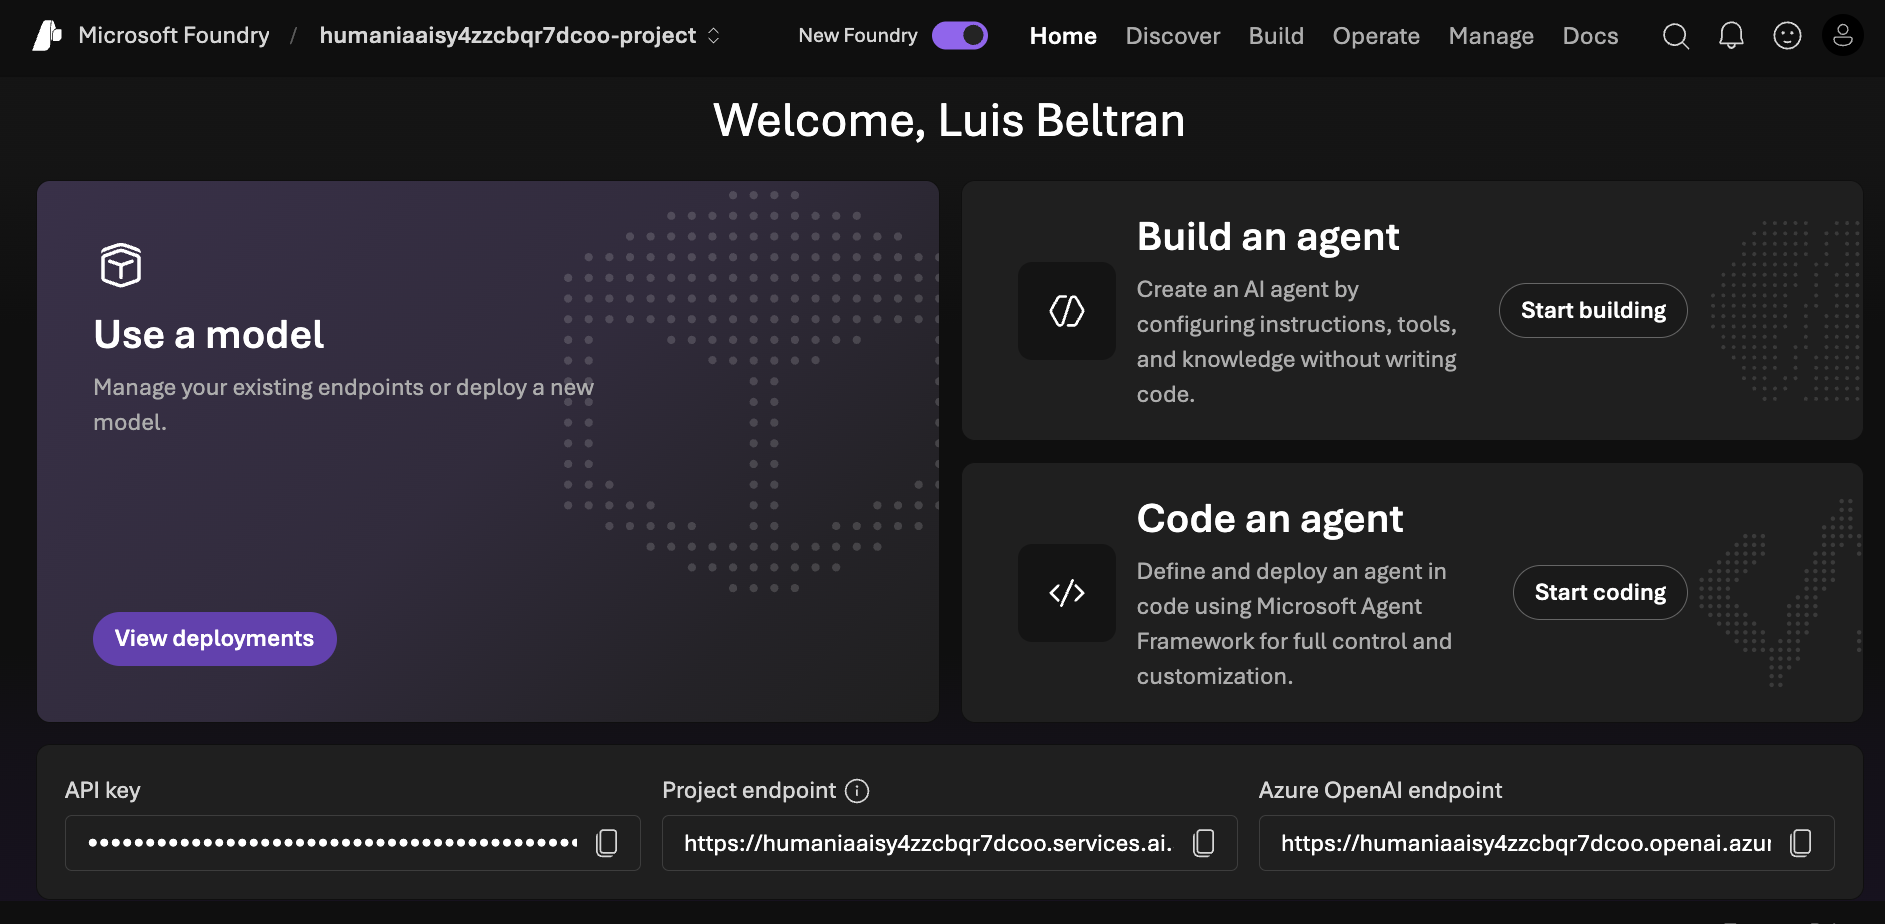

For this example, I am using a `gpt-4o-mini` model. You can deploy a base model by navigating to the **Foundry portal**, then click on **Build**, select **Models**, and finally click on **Deploy a base model**.

Use the deployment name for the `FOUNDRY_MODEL_NAME` environment variable in `.env.`

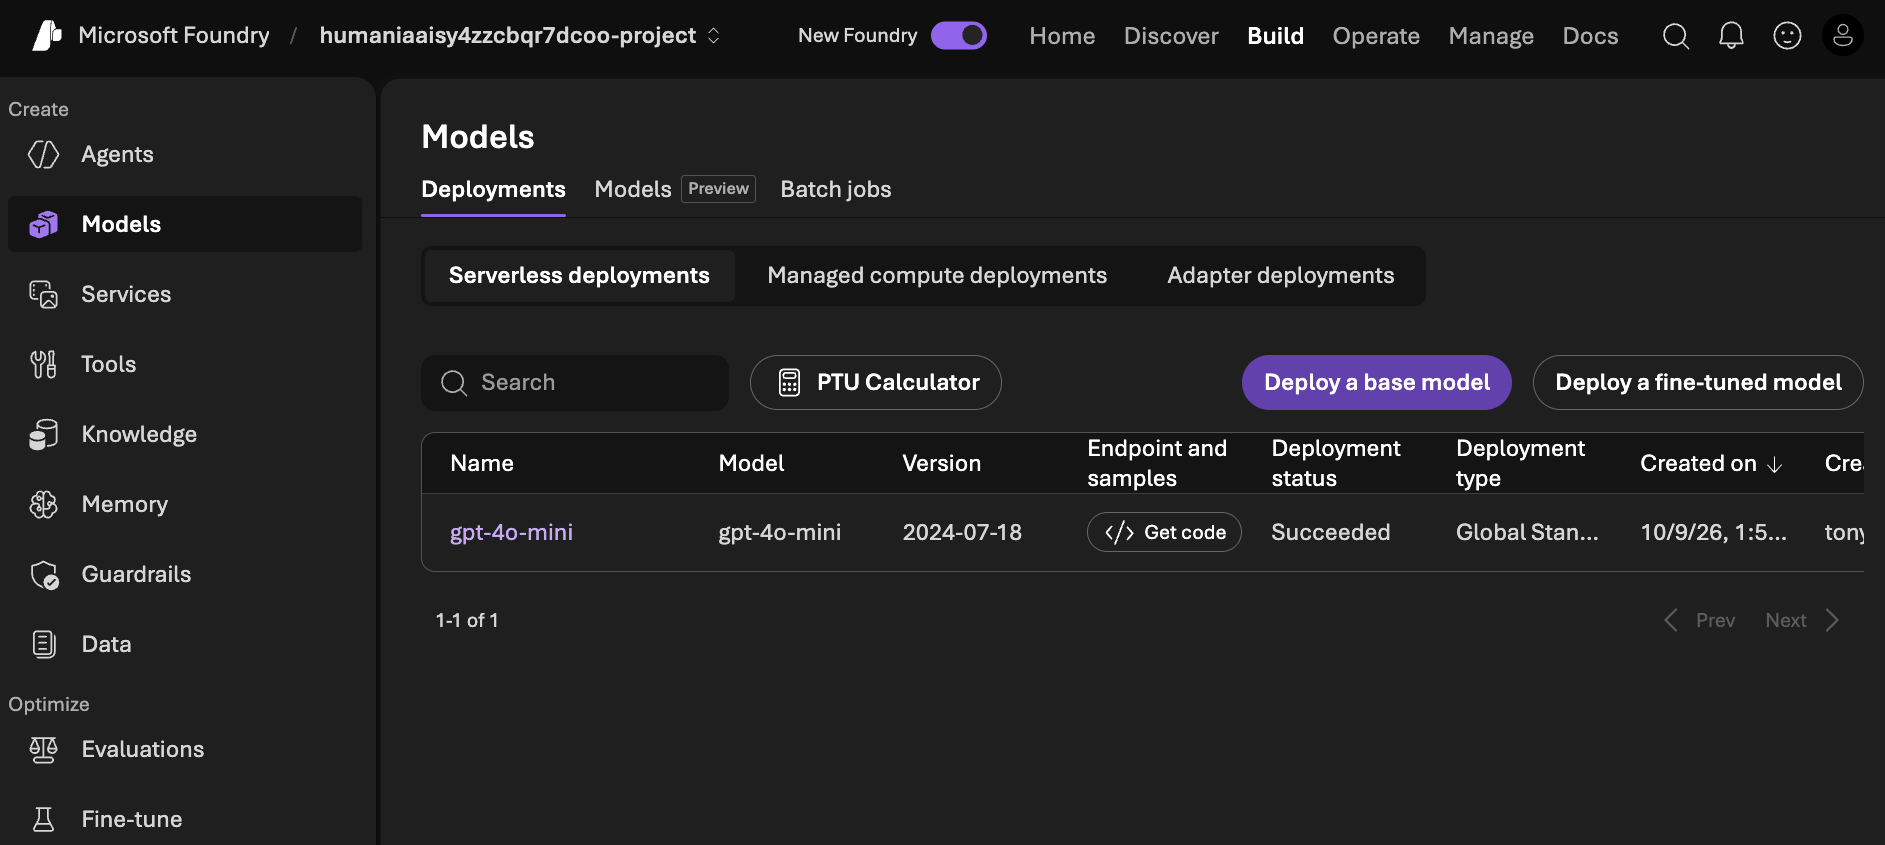

Execute the next cell to load the configuration for this tutorial

In [1]:
import os, json, re, time
from pathlib import Path
from dotenv import load_dotenv
from IPython.display import display, Markdown
from azure.identity import DefaultAzureCredential
from azure.ai.projects import AIProjectClient
from azure.ai.projects.models import PromptAgentDefinition

load_dotenv(Path.cwd() / ".env")
load_dotenv(Path.cwd().parent / ".env", override=False)

ENDPOINT = os.getenv("FOUNDRY_PROJECT_ENDPOINT", "").strip()
MODEL = os.getenv("FOUNDRY_MODEL_NAME", "").strip()
PREFIX = os.getenv("AGENT_NAME_PREFIX", "reflection-lab").strip()

assert ENDPOINT.startswith("https://") and "/api/projects/" in ENDPOINT, "Set a valid FOUNDRY_PROJECT_ENDPOINT in .env"
assert MODEL, "Set FOUNDRY_MODEL_NAME in .env"

print("Configuration loaded. Model deployment:", MODEL)
print("Foundry endpoint:", ENDPOINT)

Configuration loaded. Model deployment: gpt-4o-mini
Foundry endpoint: https://humaniaaisy4zzcbqr7dcoo.services.ai.azure.com/api/projects/humaniaaisy4zzcbqr7dcoo-project


## 3. Our scenario:

A company must choose **one** analytics SaaS vendor. The **decision policy** goes as follows:

1. Budget cap: **$100,000 annual total cost**. Above cap means ineligible.

2. Security gate: **SOC 2 Type II required**. Missing means ineligible.

3. Residency gate: **EU data residency required**. Missing means ineligible.

4. Among eligible vendors choose the **lowest annual total cost**. If tied, choose higher support rating.

5. Mention at least one meaningful drawback of the selected option and explicitly name rejected vendors with reasons.

Run the following cell to load sample data as well as setting up initial variables according to the specifications defined in the above scenario.

In [2]:
VENDORS = [
    {"name": "Northstar Analytics", "license_usd": 78000, "setup_usd": 12000, "soc2_type_ii": True, "eu_residency": True, "support_rating": 3, "drawback": "No 24/7 phone support"},
    {"name": "BluePeak Insights", "license_usd": 69000, "setup_usd": 8000, "soc2_type_ii": False, "eu_residency": True, "support_rating": 5, "drawback": "SOC 2 Type II report unavailable"},
    {"name": "Cedar Metrics", "license_usd": 82000, "setup_usd": 9000, "soc2_type_ii": True, "eu_residency": True, "support_rating": 5, "drawback": "More expensive than Northstar"},
    {"name": "Orbit Intelligence", "license_usd": 62000, "setup_usd": 10000, "soc2_type_ii": True, "eu_residency": False, "support_rating": 4, "drawback": "No EU residency"},
    {"name": "Summit BI", "license_usd": 91000, "setup_usd": 16000, "soc2_type_ii": True, "eu_residency": True, "support_rating": 5, "drawback": "Exceeds annual budget"},
]

BUDGET = 100000

TASK = ("Recommend one vendor based ONLY on the supplied data and policy. "
        "Explain the decision, show annual total costs (license + setup), rejected alternatives, "
        "and the selected vendor's main drawback. Include 'Selected Vendor: ' followed by the vendor's name in your recommendation.")

DATA = json.dumps({"budget_usd": BUDGET, "vendors": VENDORS}, indent=2)
print(DATA)

{
  "budget_usd": 100000,
  "vendors": [
    {
      "name": "Northstar Analytics",
      "license_usd": 78000,
      "setup_usd": 12000,
      "soc2_type_ii": true,
      "eu_residency": true,
      "support_rating": 3,
      "drawback": "No 24/7 phone support"
    },
    {
      "name": "BluePeak Insights",
      "license_usd": 69000,
      "setup_usd": 8000,
      "soc2_type_ii": false,
      "eu_residency": true,
      "support_rating": 5,
      "drawback": "SOC 2 Type II report unavailable"
    },
    {
      "name": "Cedar Metrics",
      "license_usd": 82000,
      "setup_usd": 9000,
      "soc2_type_ii": true,
      "eu_residency": true,
      "support_rating": 5,
      "drawback": "More expensive than Northstar"
    },
    {
      "name": "Orbit Intelligence",
      "license_usd": 62000,
      "setup_usd": 10000,
      "soc2_type_ii": true,
      "eu_residency": false,
      "support_rating": 4,
      "drawback": "No EU residency"
    },
    {
      "name": "Summit BI",
      

## 4. Create four persistent Microsoft Foundry prompt agents

We create distinct roles because planning and critique are clearer when independently visible: 

* The **writer** handles both the first draft and revised output. 

* The **critic** returns inspectable findings; it does not independently approve a purchase.

> NOTE: Re-running this cell creates a new version of each named agent. The last section optionally deletes the versions created by this notebook.

In [3]:
credential = DefaultAzureCredential(exclude_interactive_browser_credential=True)

project = AIProjectClient(endpoint=ENDPOINT, credential=credential)
openai = project.get_openai_client()

INSTRUCTIONS = {
    "writer": "You are a procurement analyst. Use only supplied facts. Clearly separate facts, calculations and recommendations. Do not invent facts. For revisions, address supplied critique and keep the final answer concise.",
    "planner": "You are a workflow planner. Break the task into concrete verification steps. Never make the vendor selection during planning. Use only the data provided.",
    "executor": "You are a meticulous procurement analyst. Execute each supplied plan step against supplied facts, showing calculations and constraints. Do not invent outside facts.",
    "critic": "You are an independent quality reviewer. Compare a draft to the stated policy and full dataset. Identify specific omissions, arithmetic mistakes, unsupported assertions, and policy violations. Do not invent problems; cite concrete vendor facts. End with 2-5 actionable revision requests. A good result can have zero issues.",
}

created_versions = []
AGENTS = {}

for role, instructions in INSTRUCTIONS.items():
    name = f"{PREFIX}-{role}"

    agent = project.agents.create_version(
        agent_name=name,
        definition=PromptAgentDefinition(model=MODEL, instructions=instructions),
    )

    created_versions.append((agent.name, agent.version))

    AGENTS[role] = agent.name

    print(f"Created {role}: {agent.name} (version {agent.version})")

Created writer: reflection-lab-writer (version 1)
Created planner: reflection-lab-planner (version 1)
Created executor: reflection-lab-executor (version 1)
Created critic: reflection-lab-critic (version 1)


You can find these agents in the Foundry portal. Click on **Build** tab, then **Agents**. As expected, they are **Prompt agents**.

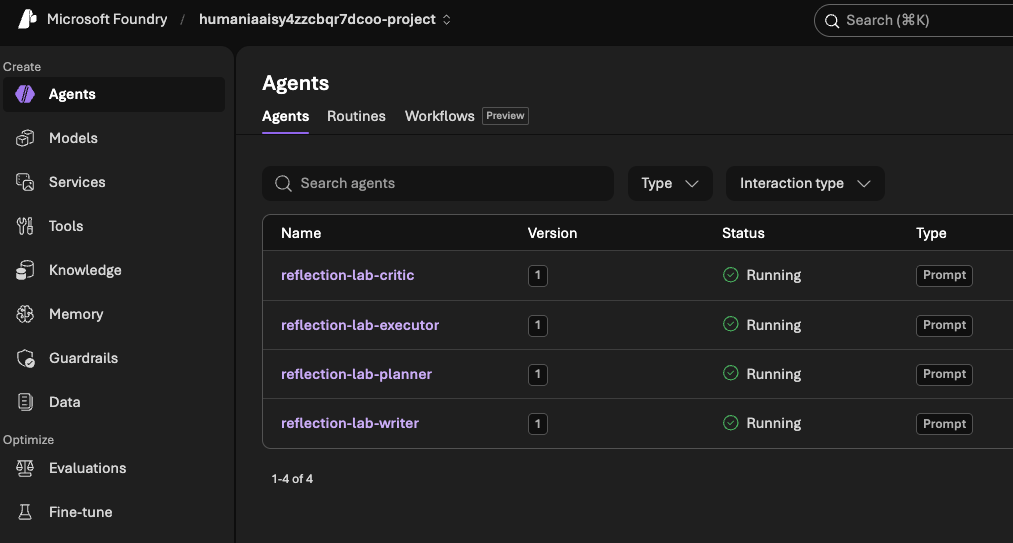

## 5. Responses API helper + basic usage tracking

Every call below uses **Foundry's agent_reference** through a Responses API request. 

Record response IDs, duration and token counts for observability.

In [4]:
RUN_LOG = []

def respond(role, input_text, previous_response_id=None):
    kwargs = {
        "input": input_text,
        "extra_body": {"agent_reference": {"name": AGENTS[role], "type": "agent_reference"}},
    }

    if previous_response_id:
        kwargs["previous_response_id"] = previous_response_id

    start = time.perf_counter()
    result = openai.responses.create(**kwargs)

    duration = time.perf_counter() - start
    usage = getattr(result, "usage", None)

    record = {
        "role": role, "response_id": result.id, "previous_response_id": previous_response_id,
        "seconds": round(duration, 2),
        "input_tokens": getattr(usage, "input_tokens", None),
        "output_tokens": getattr(usage, "output_tokens", None),
        "total_tokens": getattr(usage, "total_tokens", None),
    }

    RUN_LOG.append(record)

    return result

def show_result(title, response):
    display(Markdown(f"### {title}\n\n{response.output_text or '*No text returned*'}"))
    print("Response ID:", response.id)

## DEMO A — One-shot baseline

We start with a normal agent call: one task, one response, no explicit checkpoints. 

It might already succeed—but we cannot inspect intermediate verification steps.

In [5]:
baseline = respond("writer", f"{TASK}\n\nPOLICY AND VENDOR DATA:\n{DATA}")
show_result("Baseline recommendation", baseline)

### Baseline recommendation

### Facts
- **Budget**: $100,000
- **Vendor Data**:
  - **Northstar Analytics**: 
    - License: $78,000
    - Setup: $12,000
    - Annual Total Cost: $90,000
    - SOC 2 Type II: Yes
    - EU Residency: Yes
    - Support Rating: 3
    - Drawback: No 24/7 phone support
  - **BluePeak Insights**: 
    - License: $69,000
    - Setup: $8,000
    - Annual Total Cost: $77,000
    - SOC 2 Type II: No
    - EU Residency: Yes
    - Support Rating: 5
    - Drawback: SOC 2 Type II report unavailable
  - **Cedar Metrics**: 
    - License: $82,000
    - Setup: $9,000
    - Annual Total Cost: $91,000
    - SOC 2 Type II: Yes
    - EU Residency: Yes
    - Support Rating: 5
    - Drawback: More expensive than Northstar
  - **Orbit Intelligence**: 
    - License: $62,000
    - Setup: $10,000
    - Annual Total Cost: $72,000
    - SOC 2 Type II: Yes
    - EU Residency: No
    - Support Rating: 4
    - Drawback: No EU residency
  - **Summit BI**: 
    - License: $91,000
    - Setup: $16,000
    - Annual Total Cost: $107,000
    - SOC 2 Type II: Yes
    - EU Residency: Yes
    - Support Rating: 5
    - Drawback: Exceeds annual budget

### Calculations
1. **Northstar Analytics**: $78,000 (license) + $12,000 (setup) = $90,000
2. **BluePeak Insights**: $69,000 (license) + $8,000 (setup) = $77,000
3. **Cedar Metrics**: $82,000 (license) + $9,000 (setup) = $91,000
4. **Orbit Intelligence**: $62,000 (license) + $10,000 (setup) = $72,000
5. **Summit BI**: $91,000 (license) + $16,000 (setup) = $107,000

### Recommendations
**Selected Vendor**: Northstar Analytics

### Explanation
Northstar Analytics offers a total annual cost of $90,000, which is within the budget and encompasses both SOC 2 Type II compliance and EU residency. Although its support rating is lower than some alternatives, it is competitive in terms of pricing and compliance.

### Rejected Alternatives
- **BluePeak Insights**: Total cost $77,000, but lacks SOC 2 Type II compliance.
- **Cedar Metrics**: Total cost $91,000, slightly above budget.
- **Orbit Intelligence**: Total cost $72,000, but does not meet EU residency requirements.
- **Summit BI**: Total cost $107,000, exceeds the budget.

### Selected Vendor's Main Drawback
Northstar Analytics does not provide 24/7 phone support.

Response ID: resp_0c0a6fefba0cfedc006ad6a32bc8a0819083161428a17b4263


## DEMO B — Plan → Act

Before answering, the first agent writes a verifiable plan. The second agent executes that plan. We link the calls with `previous_response_id`.

The planner and executor are different agents. Because a cross-agent response chain may not always expose the earlier user's dataset to the second agent as expected, the execution input includes the **validated data and plan explicitly**, while retaining the response link for continuity.

Planning gives **structure**, not correctness guarantees. Our deterministic checks later test the result.

Here comes the **planner**:

In [6]:
plan_prompt = f"""Create a numbered 4-6 step verification plan for the following task.
Include arithmetic verification, each mandatory gate, ranking, and drawbacks.
Output a readable numbered list, not a final recommendation.

TASK: {TASK}
DATA: {DATA}"""

plan_result = respond("planner", plan_prompt)

show_result("Planner output", plan_result)

### Planner output

### Verification Plan for Vendor Recommendation

1. **Calculate Total Costs for Each Vendor:**
   - Compute the annual total cost for each vendor using the formula:  
     \[ \text{Total Cost} = \text{License Cost} + \text{Setup Cost} \]

2. **Budget Compliance Check:**
   - Verify that the total cost for each vendor does not exceed the budget of $100,000. This is a mandatory gate that must be satisfied for a vendor to be considered further.

3. **Evaluate Mandatory Gates:**
   - Confirm each vendor against the required criteria:  
     - SOC 2 Type II compliance
     - EU residency (if applicable)
   - Vendors failing to meet these criteria are automatically rejected.

4. **Rank Qualified Vendors:**
   - For vendors that pass the budget check and mandatory gates, rank them based on their total costs (ascending order). If needed, consider support ratings as a secondary criterion for ranking.

5. **Document Rejected Alternatives:**
   - Compile a list of vendors that were rejected during the budget and mandatory gate checks, providing a brief rationale for each.

6. **Identify Main Drawback of Selected Vendor:**
   - After determining the top-ranked vendor, note its primary drawback as indicated in the provided data for transparency in the recommendation process.

Response ID: resp_0f9985a5ed6160a8006ad6a33215a481959680eab6ff818143


And now, here's the second agent (**executor**), who executes the plan proposed by the first agent (**planner**):

In [7]:
execution_prompt = f"""Execute the following plan step by step and then give a final selection.
Use ONLY the original facts; check every gate and all total costs.

PLAN:
{plan_result.output_text}

ORIGINAL TASK:
{TASK}

ORIGINAL DATA:
{DATA}"""

execution_result = respond("executor", execution_prompt, previous_response_id=plan_result.id)

show_result("Plan-then-act recommendation", execution_result)

print("Chained to planner response:", plan_result.id)

### Plan-then-act recommendation

### Step-by-Step Execution of the Verification Plan

1. **Calculate Total Costs for Each Vendor:**
   - **Northstar Analytics:**  
     \[ \text{Total Cost} = 78000 + 12000 = 90000 \]
   - **BluePeak Insights:**  
     \[ \text{Total Cost} = 69000 + 8000 = 77000 \]
   - **Cedar Metrics:**  
     \[ \text{Total Cost} = 82000 + 9000 = 91000 \]
   - **Orbit Intelligence:**  
     \[ \text{Total Cost} = 62000 + 10000 = 72000 \]
   - **Summit BI:**  
     \[ \text{Total Cost} = 91000 + 16000 = 107000 \]

2. **Budget Compliance Check:**
   - **Northstar Analytics:** $90,000 (within budget)
   - **BluePeak Insights:** $77,000 (within budget)
   - **Cedar Metrics:** $91,000 (within budget)
   - **Orbit Intelligence:** $72,000 (within budget)
   - **Summit BI:** $107,000 (exceeds budget, **rejected**)

3. **Evaluate Mandatory Gates:**
   - **Northstar Analytics:** SOC 2 Type II: Yes; EU Residency: Yes (accepted)
   - **BluePeak Insights:** SOC 2 Type II: No; EU Residency: Yes (rejected)
   - **Cedar Metrics:** SOC 2 Type II: Yes; EU Residency: Yes (accepted)
   - **Orbit Intelligence:** SOC 2 Type II: Yes; EU Residency: No (rejected)
   - **Summit BI:** SOC 2 Type II: Yes; EU Residency: Yes (rejected due to budget issue)

4. **Rank Qualified Vendors:**
   - Remaining vendors are Northstar Analytics and Cedar Metrics.
   - **Total Costs:**
     - Northstar Analytics: $90,000
     - Cedar Metrics: $91,000
   - **Ranking (ascending order):**
     1. **Northstar Analytics** - $90,000
     2. **Cedar Metrics** - $91,000

5. **Document Rejected Alternatives:**
   - **BluePeak Insights:** Rejected due to lack of SOC 2 Type II compliance.
   - **Orbit Intelligence:** Rejected due to lack of EU residency.
   - **Summit BI:** Rejected due to exceeding the annual budget.

6. **Identify Main Drawback of Selected Vendor:**
   - **Selected Vendor:** Northstar Analytics
   - **Main Drawback:** No 24/7 phone support.

### Final Recommendation
Selected Vendor: Northstar Analytics
- **Annual Total Costs:** $90,000 (license + setup)
- **Rejected Alternatives:** BluePeak Insights (no SOC 2 compliance), Orbit Intelligence (no EU residency), Summit BI (exceeds budget).  
- **Main Drawback:** No 24/7 phone support.

Response ID: resp_0f9985a5ed6160a8006ad6a335827881958079658cbaa174e0
Chained to planner response: resp_0f9985a5ed6160a8006ad6a33215a481959680eab6ff818143


## DEMO C — Act → Reflect → Revise

A draft is not the final answer. We introduce an independent reviewer, then have the author revise against concrete gaps.

Here the critic sees the policy, full dataset and draft. The writer's revision **chains from its own draft** using `previous_response_id`. The critique text is explicitly injected into the revision request because the critic is a separate agent.

This version runs **one reflection cycle**. Production systems can repeat with bounded cycles and independent quality gates.

So, let's start by creating a **draft** using the **writer** agent:

In [8]:
draft = respond("writer", f"Prepare a concise first-pass recommendation. {TASK}\n\nFACTS:\n{DATA}")
show_result("First draft", draft)

### First draft

**First-Pass Recommendation**

**Selected Vendor: Northstar Analytics**

**Decision Explanation:**
Northstar Analytics is recommended due to its compliance with the budget and essential criteria of SOC 2 Type II and EU residency. With an annual total cost of $90,000, it fits well within the $100,000 budget.

**Annual Total Costs:**
- License: $78,000
- Setup: $12,000
- **Total: $90,000**

**Rejected Alternatives:**
1. **BluePeak Insights**: Total cost $77,000, but lacks SOC 2 Type II compliance.
2. **Cedar Metrics**: Total cost $91,000—exceeds budget limits.
3. **Orbit Intelligence**: Total cost $72,000, but lacks EU residency.
4. **Summit BI**: Total cost $107,000—exceeds budget limits.

**Main Drawback of Selected Vendor:**
Northstar Analytics does not offer 24/7 phone support.

Response ID: resp_00a4307e2bd28058006ad6a33b53ac8190bd7dd264d472c929


Then, the **critic** agent can use the generated draft as input to write an independent review. It is possible that this agent finds gaps, omissions, policy violations, or simply provides a new perspective:

In [9]:
critique_prompt = f"""Review this draft against every mandatory rule and all supplied facts.
Do not assume the draft is wrong; report evidence-based gaps and specific repairs.

POLICY: {TASK}
FULL DATA: {DATA}
DRAFT: {draft.output_text}
"""

critique = respond("critic", critique_prompt)
show_result("Independent critique", critique)

### Independent critique

### Review of Draft Against Policy and Dataset

#### Identified Issues:

1. **Supporting Evidence for Decision**:
   - **Issue**: The draft states that Northstar Analytics is recommended based on two criteria (SOC 2 Type II compliance and EU residency). However, while SOC 2 Type II compliance is confirmed, the assertion that it meets essential criteria isn't fully supported by comparison with alternatives. Among the rejected vendors, BluePeak Insights has a higher support rating, and Cedar Metrics offers similar criteria with higher support ratings too.
   - **Evidence**: Cedar Metrics and Orbit Intelligence also satisfy most essential criteria but with better support ratings.

2. **Total Cost Calculation for Rejected Vendors**:
   - **Error**: The calculation for the total cost of BluePeak Insights was not included in the total cost narrative, which leads to confusion. The stated total cost ($77,000) aligns with the formula but is inaccurately reported as being adequate even though it lacks SOC 2 Type II, which is a core requirement.
   - **Correction**: Clarify the exclusion criteria based on SOC 2 Type II necessity and explain the potential risks of selecting a vendor without this compliance.

3. **Exceeding Budget Clarification**:
   - **Issue**: While it is stated that Summit BI exceeds the budget, Cedar Metrics does too ($91,000), yet it is still noted in the rejected alternatives with a vague outcome of “exceeds budget limits.” This could confuse readers regarding which metrics and criteria were strictly considered when rejecting these vendors.
   - **Correction**: Clearly specify how each vendor fits the criteria related to budget constraint more explicitly.

4. **Lack of Mention for Alternatives’ Support Ratings**:
   - **Issue**: The draft does not discuss the vendor support ratings adequately, which could be considered a key decision factor. BluePeak and Cedar Metrics both have a rating of 5, superior to Northstar's rating of 3.
   - **Evidence**: Support ratings are critical in evaluating vendor offerings, especially when considering customer support after implementation.

5. **Final Recommendation Justification**:
   - **Issue**: While the drawback of Northstar is identified, the draft should elaborate on how this specific limitation could impact operations, particularly for a company that may require immediate assistance.
   - **Correction**: Provide potential implications of having no 24/7 support, especially if the business has critical operations.

### Actionable Revision Requests:

1. **Enhance Decision Justification**: Strengthen the rationale for the selection of Northstar Analytics by including a comparison of support ratings and discussing their relevance to operational needs.

2. **Clarify Total Cost Calculations**: Ensure clarity in rejected alternatives with accurate cost figures and reiterate why vendors were excluded based on core requirements.

3. **Include Alternative Support Ratings in Evaluation**: Explicitly discuss the support ratings of the rejected alternatives to provide a well-rounded perspective on customer service implications.

4. **Expand on Selected Vendor Drawbacks**: Elaborate on the potential operational impact of Northstar Analytics not offering 24/7 phone support, considering the needs for immediate assistance in business operations.

5. **Revise Budget Analysis**: Clearly articulate how each vendor raises concerns regarding budget compliance and the importance of ensuring that selected vendors remain within budget limits alongside compliance standards.

Response ID: resp_04ec296b59c13ec9006ad6a33e6f808196bc00b59d7bf5d85e


Finally, use the **writer** agent again to write a final recommendation, which revises the draft that was generated originally and considers the information found by the independent review generated by the **critic** agent:

In [10]:
revision_prompt = f"""Revise your original draft to address the independent critique.
Explicitly fix any supported errors, and do not invent data.
If the critique raises a false issue, explain briefly why it is not a defect.

INDEPENDENT CRITIQUE:
{critique.output_text}

ORIGINAL TASK:
{TASK}
FULL DATA:
{DATA}"""

revised = respond("writer", revision_prompt, previous_response_id=draft.id)

show_result("Refined recommendation", revised)
print("Revision chained to original draft:", draft.id)

### Refined recommendation

**First-Pass Recommendation**

**Selected Vendor: Northstar Analytics**

**Decision Explanation:**
Northstar Analytics is selected due to its compliance with the budget and key requirements of SOC 2 Type II and EU residency. While support ratings are indeed relevant, Northstar's cost-effectiveness within the budget outweighs its lower support rating compared to others. Its annual total cost is $90,000, fitting comfortably within the $100,000 ceiling.

**Annual Total Costs:**
- License: $78,000
- Setup: $12,000
- **Total: $90,000**

**Rejected Alternatives:**
1. **BluePeak Insights**: Total cost $77,000, but lacks SOC 2 Type II compliance. Higher support rating (5) does not compensate for this critical compliance risk.
2. **Cedar Metrics**: Total cost $91,000—exceeds budget limits. While it has a support rating of 5, the cost makes it less favorable.
3. **Orbit Intelligence**: Total cost $72,000—lacks EU residency, a significant compliance concern despite a support rating of 4.
4. **Summit BI**: Total cost $107,000—exceeds budget limits. Although having a high support rating (5), it is not financially feasible.

**Support Ratings Comparison:**
- Northstar Analytics: 3 
- BluePeak Insights: 5 
- Cedar Metrics: 5 
- Orbit Intelligence: 4 
- Summit BI: 5 

While Northstar Analytics has the lowest support rating, the balance of compliance and cost makes it preferable given the budget constraints.

**Main Drawback of Selected Vendor:**
The primary drawback of Northstar Analytics is the lack of 24/7 phone support. This may impact operations requiring immediate assistance, particularly during critical periods when prompt support is essential for addressing urgent issues.

In comparison, higher-rated alternatives could provide better ongoing support, but compliance and budget considerations ultimately lead to the recommendation of Northstar Analytics.

Response ID: resp_00a4307e2bd28058006ad6a3447c008190985cfa9b01c03383
Revision chained to original draft: resp_00a4307e2bd28058006ad6a33b53ac8190bd7dd264d472c929


## 6. Deterministic ground truth and comparison

The critic and writer are probabilistic. **Quality must be checked independently.** 

The following basic evaluator uses objective source data to identify the correct eligible vendor. An optional text-based checklist is a *demo heuristic*, not semantic correctness evaluation.

In [11]:
def eligible(v):
    return (v["license_usd"] + v["setup_usd"] <= BUDGET
            and v["soc2_type_ii"] and v["eu_residency"])

ranked = sorted((v for v in VENDORS if eligible(v)),
                key=lambda v: (v["license_usd"] + v["setup_usd"], -v["support_rating"]))

winner = ranked[0]

print("Ground-truth qualified vendors:", [(v["name"], v["license_usd"]+v["setup_usd"]) for v in ranked])
print("Expected recommendation:", winner["name"])
assert winner["name"] == "Northstar Analytics"

# These are surface-level indicators, NOT proof the answer is correct.
def checklist(text):
    t = text.lower()

    normalized = re.sub(r"[*_`~]", "", t).lower() # remove markdown formatting and lowercase
    expected = f"selected vendor: {winner['name']}".lower()

    return {
        "mentions_expected_winner": expected in normalized,
        "mentions_all_vendors": all(v["name"].lower() in t for v in VENDORS),
        "mentions_security_gate": "soc 2" in t or "soc2" in t,
        "mentions_residency": "residen" in t,
        "mentions_a_drawback": "support" in t or "drawback" in t or "limitation" in t,
    }

outputs = {"One-shot": baseline.output_text or "", "Plan → Act": execution_result.output_text or "", "Reflect → Revise": revised.output_text or ""}

for name, text in outputs.items():
    flags = checklist(text)

    print(f"\n{name}: {sum(flags.values())}/{len(flags)} surface-level checks")

    for k, ok in flags.items():
        print("  ", "PASS" if ok else "CHECK", k)

Ground-truth qualified vendors: [('Northstar Analytics', 90000), ('Cedar Metrics', 91000)]
Expected recommendation: Northstar Analytics

One-shot: 5/5 surface-level checks
   PASS mentions_expected_winner
   PASS mentions_all_vendors
   PASS mentions_security_gate
   PASS mentions_residency
   PASS mentions_a_drawback

Plan → Act: 5/5 surface-level checks
   PASS mentions_expected_winner
   PASS mentions_all_vendors
   PASS mentions_security_gate
   PASS mentions_residency
   PASS mentions_a_drawback

Reflect → Revise: 5/5 surface-level checks
   PASS mentions_expected_winner
   PASS mentions_all_vendors
   PASS mentions_security_gate
   PASS mentions_residency
   PASS mentions_a_drawback


## 7. Token usage, latency and the cost of iteration

Each additional model call creates overhead. These numbers are **observed usage**, not a normalized price comparison: different roles and inputs use different token counts.

In [12]:
from collections import defaultdict
for r in RUN_LOG:
    print(f"{r['role']:9} {r['seconds']:6.2f}s  "
          f"input={r['input_tokens']} output={r['output_tokens']} total={r['total_tokens']}")
print("\nTotal model calls:", len(RUN_LOG))
print("Total reported tokens:", sum(r['total_tokens'] or 0 for r in RUN_LOG))

writer      7.24s  input=486 output=711 total=1197
planner     2.99s  input=513 output=270 total=783
executor    6.27s  input=1527 output=642 total=2169
writer      3.06s  input=489 output=208 total=697
critic      6.07s  input=746 output=676 total=1422
writer      5.27s  input=1865 output=412 total=2277

Total model calls: 6
Total reported tokens: 8545


## 8. Additional challenges / considerations

You can try the following exercises to understand the impact of **Reflection and Planning**:

1. Deliberately remove a mandatory rule from the writer instructions or use a shorter first-pass prompt. Does the **critic** catch the omission?

2. Run a second **critique → revise** cycle only if independent checks fail. Never allow unbounded iteration.

3. Require the **planner** to output JSON and validate the schema before executing. The response format supported by your model can be requested via `text.format` / `extra_body`.

4. You can use this approach for a **code review task**, where the **critic** checks input validation, error handling, secrets and performance. Use external tests or a linter to judge the result.

**Discussion:** 

* When would you use no reflection? 

* When is an independent critic insufficient? 

* What happens if both models confidently agree on a wrong assumption?

Feel free to answer these questions or post your queries in the [**Discussions**](https://github.com/icebeam7/reflection-planning-foundry/discussions) forum

## Conclusion

* Planning organizes work

* Reflection creates an explicit opportunity for correction

* External validation determines whether the output is acceptable.

* **Agents become more dependable when we design the process around them: plan, execute, question the output, validate, and revise only when needed.**

## 9. Optional cleanup — remove only the agent versions from this notebook

Skip cleanup if you want to inspect your agents in Microsoft Foundry. Response history and project-level telemetry may have their own retention/cleanup policies.

In [ ]:
# Uncomment and run ONLY if you want to delete the versions created above.

# for agent_name, agent_version in reversed(created_versions):
#     project.agents.delete_version(agent_name=agent_name, agent_version=agent_version)
#     print("Deleted", agent_name, agent_version)
# openai.close()
# project.close()
# credential.close()

## Resources

- [Implement agent reflection and planning cycles — Microsoft Learn](https://learn.microsoft.com/en-us/training/modules/aaai-design-agentic-loops-azure-ai-agent-service/4-implement-agent-reflection-planning-cycles)

- [Foundry prompt agent quickstart](https://learn.microsoft.com/en-us/azure/foundry/agents/quickstarts/prompt-agent)

- [Azure AI Projects Python SDK](https://learn.microsoft.com/en-us/python/api/overview/azure/ai-projects-readme)